# Componente 3 — Una segunda mirada: comparación de enfoques y casos raros

**Ventana:** 1 de enero a 31 de agosto de 2026. **Universo:** los 58,275 viajes de `tc.cargar_universo()`. Se compara la misma demanda observada; no son pronósticos ni ahorros garantizados. Las capacidades legales dependen de taras provisionales y el peso no informa volumen ni dimensiones. Las alternativas son escenarios independientes, no se suman.

In [1]:
# Rutas: el notebook vive en analisis_estadistico_IA/, pero data/, config/ y resultados_ternium/ están en la raíz.
# Se trabaja desde la raíz y se agregan las carpetas de código al path para importar sus módulos.
import os, sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == 'analisis_estadistico_IA' else Path.cwd()
os.chdir(RAIZ)
for _carpeta in ('analisis_estadistico_IA', 'data_processing'):
    if str(RAIZ / _carpeta) not in sys.path:
        sys.path.insert(0, str(RAIZ / _carpeta))

# Propósito: Cargar el universo común (58,275 viajes) y preparar el optimizador del Componente 2 (tarifas de
# referencia ruta × unidad, capacidades y disponibilidad de flota).
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ternium_comun as tc
import componente_3_optimizacion as opt
tc.aplicar_estilo()
df = tc.cargar_universo().reset_index(drop=True)
df['Programado_t'] = df['Programado_kg'] / 1000
assert len(df) == 58275
opt.preparar_optimizador(df)
T = opt.tarifas()
# k0 = unidad actual de cada viaje; rr = índice de su ruta; cap = carga útil legal por unidad
k0 = opt.o.k0.to_numpy(); rr = opt.o.r.to_numpy()
cap = opt.CAP_LEG
print(f"Universo: {len(df):,} viajes; {df.FECHA_EGRESO.min():%Y-%m-%d} a {df.FECHA_EGRESO.max():%Y-%m-%d}")

Universo: 58,275 viajes; 2026-01-01 a 2026-08-31


## 1. Cuatro perspectivas en igualdad de condiciones

**Actual:** viajes y costos observados. **Heurística:** probar primero la unidad más frecuente de la ruta y, si no es elegible, la más pequeña compatible; solo se cambia si cumple las mismas reglas de tarifa, peso y materialidad del modelo. **MILP:** asignación de C2 con disponibilidad semanal por planta. Para ambos, el costo contrafactual es el costo observado menos la diferencia de medianas ruta × unidad, como en C2; se conserva la variación observada de cada viaje. La heurística no impone disponibilidad, por lo que no tiene necesariamente la misma factibilidad de flota.

**Consolidación:** First-Fit Decreasing sobre peso programado, por día, planta y destino, para viajes existentes de **3 ejes en la misma ruta**; cada bulto es indivisible y la suma no puede exceder 36.575 t. Se conserva el viaje más pesado de cada grupo y su costo observado; los demás se eliminan. La carga real se suma para las métricas físicas. Se asume misma tarifa, producto compatible, horarios compatibles y capacidad suficiente al consolidar: son supuestos por verificar. No se aplica right-sizing simultáneo. El dato es viaje, no pedido: se asume que cada viaje puede tratarse como carga indivisible.

In [2]:
# Elegibilidad común a los dos escenarios de asignación de unidad
C, tarifa0 = opt.factibles(T)
# Frecuencia de cada unidad por ruta
freq = pd.crosstab(opt.o['r'], opt.o['k0']).reindex(index=range(len(opt.rutas_o)), columns=range(opt.K), fill_value=0).to_numpy()
# Heurística: entre las unidades factibles, la más frecuente en la ruta; si no es factible, la de menor capacidad
k_h = k0.copy()
for i in range(len(df)):
    candidatos = np.flatnonzero(np.isfinite(C[i]))
    candidatos = candidatos[candidatos != k0[i]]
    if len(candidatos):
        mas = int(np.argmax(freq[rr[i]]))
        k_h[i] = mas if mas in candidatos else candidatos[np.argmin(opt.CAP_LEG[candidatos])]
# MILP del Componente 2 (con disponibilidad semanal de flota)
k_m, _ = opt.resolver(T, con_flota=True)

def asignacion(k):
    """Ahorro por viaje = tarifa de referencia de la unidad actual − la de la unidad asignada."""
    mueve = k != k0
    ahorro = np.zeros(len(df))
    ahorro[mueve] = T[rr[mueve], k0[mueve]] - T[rr[mueve], k[mueve]]
    return ahorro
ah_h, ah_m = asignacion(k_h), asignacion(k_m)
print(f'MILP: {sum(k_m != k0):,} cambios; ahorro {ah_m.sum()/1e6:.2f} M MXN')

MILP: 4,721 cambios; ahorro 31.60 M MXN


In [3]:
# FFD: los grupos excluyen rutas ambiguas y cargas programadas inválidas.
q = df.Programado_t.to_numpy(); qr = df.Toneladas_Reales.to_numpy()
activo = np.ones(len(df), dtype=bool); carga_c = qr.copy(); interv_c = np.zeros(len(df), dtype=bool)
elegible = ((df.Unidad.astype(str) == '3 Ejes') & df.Ruta_ID.notna() & df['Ciudad Destino'].notna()
            & (df.Programado_t > 0) & (df.Programado_t <= 36.575) & (df.Toneladas_Reales > 0))
g = df.loc[elegible].groupby([df.FECHA_EGRESO.dt.normalize(), tc.PLANTA, 'Ciudad Destino', 'Ruta_ID'], observed=True, dropna=True)
# First-Fit Decreasing: dentro de cada grupo, las cargas (de mayor a menor) entran al primer camión donde caben
for _, grupo in g:
    bins = []
    for i in grupo.index[np.argsort(-q[grupo.index], kind='stable')]:
        for b in bins:
            if b[0] + q[i] <= 36.575 + 1e-9:
                b[0] += q[i]; b[1].append(i); break
        else:
            bins.append([q[i], [i]])
    # Camiones con más de una carga: se conserva el más pesado y los demás viajes se eliminan
    for _, ids in bins:
        if len(ids) > 1:
            lider, resto = ids[0], ids[1:]
            activo[resto] = False; carga_c[lider] = qr[ids].sum(); carga_c[resto] = 0
            interv_c[ids] = True
# Ahorro = costo de los viajes eliminados
ah_c = np.where(~activo, df.Costo.to_numpy(), 0)
print(f'Consolidación: {interv_c.sum():,} viajes involucrados; {(~activo).sum():,} viajes eliminados.')

Consolidación: 74 viajes involucrados; 37 viajes eliminados.


### Comparación e incertidumbre

Los intervalos del 95 % son bootstrap de dos vías **transportista × ruta**, con escenarios fijos y pesos pareados: reflejan variación de la mezcla observada, no recalibran tarifas, optimización ni empaquetado. Totales normalizados a 58,275 viajes, como en el simulador de C2; los intervalos no son bandas de predicción. Las medianas usan el mismo remuestreo de dos vías con pesos multinomiales; la función compartida `tc.bootstrap_conglomerados` calcula los intervalos de razones y totales normalizados. Para la consolidación, el remuestreo trata el grupo empacado como fijo y atribuye sus resultados a los viajes originales: la incertidumbre de la factibilidad y de la composición de grupos queda fuera.

Utilización y costo por ton-km son medianas por viaje resultante; este último usa solo km confiables. Costo/ton es gasto total dividido entre toneladas transportadas. Capacidad ociosa suma `max(capacidad legal − carga real, 0)` por viaje resultante; no se compensa sobrecarga con ociosidad. En escenarios de asignación el número intervenido son cambios de unidad; en consolidación, viajes originales involucrados, no eliminados.

In [4]:
# Propósito: Comparar los cuatro escenarios (actual, heurística, MILP y consolidación) con IC por bootstrap de
# dos vías transportista × ruta.
N=len(df); B=500
km = df.Kilometros_Ruta.to_numpy(); confiable = df.Km_Confiable.fillna(False).astype(bool).to_numpy()
costo = df.Costo.to_numpy(dtype=float)

def escenario(nombre, k, ahorro, interv, activos=None, carga=None):
    """Tabla por viaje de un escenario: costo nuevo, utilización, capacidad ociosa y costo por t-km."""
    activos = np.ones(N, bool) if activos is None else activos
    carga = qr.copy() if carga is None else carga
    capacidad = cap[k]
    nuevo = costo - ahorro
    util = np.divide(carga, capacidad, out=np.full(N, np.nan), where=activos & (capacidad>0))
    tkm = np.divide(nuevo, carga*km, out=np.full(N, np.nan), where=activos & confiable & (carga>0) & (km>0))
    return pd.DataFrame({'Escenario':nombre, 'Transportista':df.Transportista, 'Ruta_ID':df.Ruta_ID,
      'interv':interv.astype(float), 'ociosa':np.where(activos, np.maximum(capacidad-carga,0),0),
      'gasto':nuevo, 'ahorro':ahorro, 'ton':qr, 'uno':1., 'util':util, 'tkm':tkm})
base=escenario('Actual', k0, np.zeros(N), np.zeros(N,bool))
h=escenario('Heurística', k_h, ah_h, k_h!=k0)
milp=escenario('MILP con flota', k_m, ah_m, k_m!=k0)
con=escenario('Consolidación FFD', k0, ah_c, interv_c, activo, carga_c)
frames=[base,h,milp,con]
allsc=pd.concat(frames,ignore_index=True)
assert allsc[['Transportista','Ruta_ID']].notna().all().all()
sumas={x:x for x in ['interv','ociosa','gasto','ahorro','ton','uno']}
razones={x:(x,'uno') for x in ['interv','ociosa','gasto','ahorro']}; razones['costo_ton']=('gasto','ton')
boot=tc.bootstrap_conglomerados(allsc, ['Escenario'], sumas, razones, B=B, semilla=2026)

# Mismas muestras de conglomerados para medianas ponderadas y escenarios pareados.
ct, ut = pd.factorize(df.Transportista); cr, ur = pd.factorize(df.Ruta_ID)
rng=np.random.default_rng(2026)
wt=rng.multinomial(len(ut), np.full(len(ut),1/len(ut)), size=B)
wr=rng.multinomial(len(ur), np.full(len(ur),1/len(ur)), size=B)
def mediana_ic(x):
    """Mediana con IC 95 %, usando los mismos pesos de bootstrap (transportista × ruta) en todos los escenarios."""
    ok=np.isfinite(x); ids=np.flatnonzero(ok); ids=ids[np.argsort(x[ids],kind='stable')]
    vals=x[ids]; out=[]
    for j in range(B):
        w=wt[j,ct[ids]]*wr[j,cr[ids]]; acum=np.cumsum(w)
        out.append(vals[np.searchsorted(acum,acum[-1]/2,side='left')] if acum[-1] else np.nan)
    return np.nanmedian(x), *np.nanpercentile(out,[2.5,97.5])
def fmt(v, lo, hi, d=1): return f'{v:,.{d}f} [{lo:,.{d}f}–{hi:,.{d}f}]'
filas=[]
for f in frames:
    nombre=f.Escenario.iloc[0]; row=boot.loc[nombre]; a={}
    for col, escala, dec in [('interv',N,0),('ociosa',N/1000,1),('gasto',N/1e6,1),('ahorro',N/1e6,1),('costo_ton',1,0)]:
        a[col]=fmt(row[col]*escala,row[col+'_inf']*escala,row[col+'_sup']*escala,dec)
    a['util']=fmt(*mediana_ic(f.util.to_numpy()),2)
    a['tkm']=fmt(*mediana_ic(f.tkm.to_numpy()),2)
    filas.append(a)
tabla=pd.DataFrame(filas,index=[f.Escenario.iloc[0] for f in frames]).rename(columns={'interv':'Viajes intervenidos','util':'Utilización mediana','ociosa':'Ociosa (kt)','gasto':'Gasto (M MXN)','ahorro':'Ahorro (M MXN)','tkm':'Costo/t-km mediano','costo_ton':'Costo/ton'})
display(tabla)

,Viajes intervenidos,Ociosa (kt),Gasto (M MXN),Ahorro (M MXN),Costo/ton,Utilización mediana,Costo/t-km mediano
Actual,0 [0–0],442.4 [398.8–485.7],"1,636.5 [1,355.9–1,936.0]",0.0 [0.0–0.0],"980 [812–1,170]",0.81 [0.78–0.84],1.75 [1.62–1.94]
Heurística,"5,377 [2,866–9,350]",426.3 [386.8–463.0],"1,605.2 [1,328.0–1,904.6]",31.2 [16.6–54.8],"961 [798–1,146]",0.81 [0.79–0.85],1.71 [1.59–1.90]
MILP con flota,"4,721 [2,400–8,343]",427.0 [386.7–463.8],"1,604.9 [1,328.5–1,903.8]",31.6 [16.7–55.2],"961 [797–1,147]",0.81 [0.79–0.85],1.70 [1.59–1.90]
Consolidación FFD,74 [25–152],441.0 [398.1–483.9],"1,635.8 [1,354.7–1,935.5]",0.7 [0.1–1.8],"979 [811–1,170]",0.81 [0.78–0.84],1.75 [1.62–1.94]


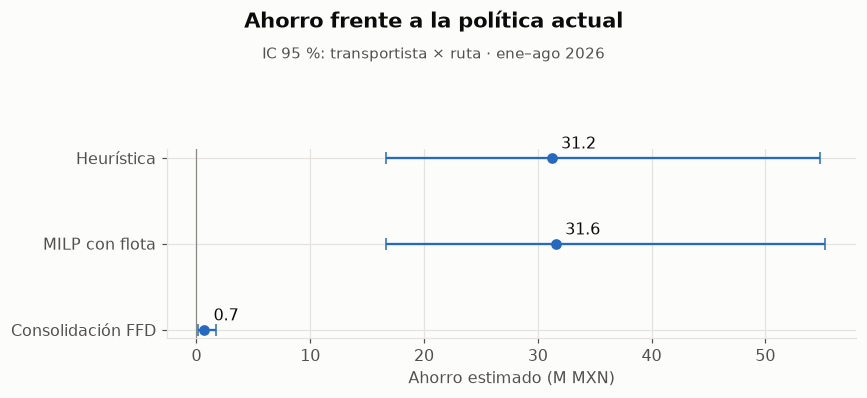

In [5]:
# FIG — Ahorro de cada escenario frente a la política actual, con IC 95 %
fig, ax = plt.subplots(figsize=(8,3.7))
for j, nombre in enumerate(['Heurística','MILP con flota','Consolidación FFD']):
    r=boot.loc[nombre]; v=r.ahorro*N/1e6; lo=r.ahorro_inf*N/1e6; hi=r.ahorro_sup*N/1e6
    ax.errorbar(v,j,xerr=[[max(0,v-lo)],[max(0,hi-v)]],fmt='o',color=tc.SECUENCIAL[4],capsize=4)
    ax.annotate(f'{v:.1f}',(v,j),xytext=(6,6),textcoords='offset points')
ax.set_yticks(range(3),['Heurística','MILP con flota','Consolidación FFD']); ax.invert_yaxis(); ax.set_xlabel('Ahorro estimado (M MXN)'); ax.axvline(0,color=tc.TINTA_3,lw=.8)
tc.titulo(fig,'Ahorro frente a la política actual','IC 95 %: transportista × ruta · ene–ago 2026')
plt.show()

## 2. Discusión crítica

La política actual describe lo que ocurrió, incluidas restricciones comerciales y urgencias no observadas, pero no identifica decisiones evitables. La heurística es sencilla y transparente, aunque ignora la disponibilidad semanal y puede elegir una alternativa que no sea la más barata. El MILP incorpora esa disponibilidad aproximada y busca el menor costo entre opciones elegibles; su máximo semanal observado no equivale a unidades físicas garantizadas y las tarifas históricas no son ofertas. Ninguna asignación verifica dimensiones, producto, horario o requisitos del cliente.

FFD explora otra palanca y conserva cada carga indivisible. No reoptimiza flota ni comprueba ventanas de entrega, secuencia de carga o negociación de tarifa. En una operación donde las cargas individuales rondan 26–30 t, dos cargas típicas no caben en 36.575 t: la capacidad vacía agregada no implica que se puedan juntar pedidos. No es un problema de paquetería. Esta conclusión debe contrastarse con la composición real de pedidos dentro de cada viaje.

In [6]:
# Propósito: Cifras de la discusión: cuánto del ahorro del MILP captura la heurística y por qué casi no se puede consolidar.
ratio=ah_h.sum()/ah_m.sum() if ah_m.sum() else np.nan
print(f'La heurística captura {ratio:.1%} del ahorro del MILP; puede superar 100 % porque no respeta su límite de flota.')
print(f'Peso real medio / mediano: {np.mean(qr):.1f} / {np.median(qr):.1f} t; límite FFD: 36.575 t.')
print(f'En FFD: {interv_c.sum():,} viajes involucrados, {(~activo).sum():,} eliminados; ahorro estimado {ah_c.sum()/1e6:.2f} M MXN.')

La heurística captura 98.8% del ahorro del MILP; puede superar 100 % porque no respeta su límite de flota.
Peso real medio / mediano: 28.7 / 29.5 t; límite FFD: 36.575 t.
En FFD: 74 viajes involucrados, 37 eliminados; ahorro estimado 0.70 M MXN.


## 3. Diagnóstico de casos raros: 20 observaciones que contradicen el patrón

Son señales para investigación, no errores ni evidencia de causalidad. En sobrecosto y subcosto se compara el costo con la mediana de ruta × unidad × transportista, siempre con al menos cinco registros; se escogen extremos por razón. Peso: mayores cargas de 2 ejes frente al P99 operativo. Inversión: rutas con al menos cinco viajes por cada unidad donde la mediana de 2 ejes supera a la de 3 ejes; se selecciona un viaje de 2 ejes por ruta. Se evitan IDs repetidos; orden determinista. No se eliminan atípicos del universo.

In [7]:
# Propósito: Seleccionar 20 casos raros (5 por familia) que contradicen el patrón, para investigarlos con Ternium.
d=df.copy(); d['unidad']=d.Unidad.astype(str)
keys=['Ruta_ID','unidad','Transportista']
# Costo de referencia: mediana de ruta × unidad × transportista (se exigen ≥ 5 viajes)
grp=d.groupby(keys,observed=True).Costo
med=grp.transform('median'); count=grp.transform('size')
d['ref']=med; d['ratio']=d.Costo/med.where(med>0)
valid=(count>=5)&(med>0)&(d.Costo>0)
selecciones=[]; usados=set()
def tomar(candidatos, familia, diag, evidencia, ref_col='ref'):
    """Agrega los 5 primeros candidatos no usados, con su familia, diagnóstico y evidencia a pedir."""
    candidatos=candidatos[~candidatos.ID_VIAJE.isin(usados)].drop_duplicates('ID_VIAJE').head(5).copy()
    usados.update(candidatos.ID_VIAJE)
    candidatos['Familia']=familia; candidatos['Diagnóstico provisional']=diag; candidatos['Evidencia requerida']=evidencia
    candidatos['Costo esperado / mediana']=candidatos[ref_col]
    selecciones.append(candidatos)
tomar(d[valid].sort_values('ratio',ascending=False), 'Sobrecosto extremo','Posible urgencia, spot o cargo extraordinario','Orden, contrato, desglose del flete y urgencia')
tomar(d[valid].sort_values('ratio'), 'Subcosto extremo','Posible retorno, crédito o ajuste','Factura, nota de crédito, contrato y viaje de retorno')
p99=tc.capacidades(df).loc['2 Ejes','Techo_P99_t']
tomar(d[d.unidad.eq('2 Ejes')].sort_values('Toneladas_Reales',ascending=False), 'Peso y equipo',f'Peso elevado frente a P99 de 2 ejes ({p99:.1f} t); verificar equipo','Báscula, tara, configuración, permiso y unidad declarada')
# Inversión tarifaria: rutas donde la mediana de 2 ejes supera a la de 3 ejes
tar=d.groupby(['Ruta_ID','unidad'],observed=True).Costo.agg(['median','size']).reset_index()
a=tar[(tar.unidad=='2 Ejes') & (tar['size']>=5)].merge(tar[(tar.unidad=='3 Ejes') & (tar['size']>=5)],on='Ruta_ID',suffixes=('_2','_3'))
a=a[a.median_2>a.median_3].sort_values('Ruta_ID')
inv=d[d.unidad.eq('2 Ejes')].merge(a[['Ruta_ID','median_3','median_2']],on='Ruta_ID')
inv=inv[inv.Costo > inv.median_3].sort_values(['Ruta_ID','ID_VIAJE']).drop_duplicates('Ruta_ID')
tomar(inv,'Inversión tarifaria','Mediana de 2 ejes mayor que la de 3 ejes en la misma ruta','Contratos, fechas, transportistas, servicio y comparabilidad','median_3')
casos=pd.concat(selecciones,ignore_index=True)
assert len(casos)==20 and casos.ID_VIAJE.nunique()==20
casos=casos.drop(columns=['Unidad']).rename(columns={'PLANTA_ORIGEN':'Planta','Ciudad Destino':'Destino','unidad':'Unidad','Toneladas_Reales':'Peso (t)','Costo':'Costo real (MXN)'})
cols=['Familia','ID_VIAJE','Planta','Destino','Unidad','Peso (t)','Costo real (MXN)','Costo esperado / mediana','Diagnóstico provisional','Evidencia requerida']
display(casos[cols].round({'Peso (t)':1,'Costo esperado / mediana':0}))
print('En peso y equipo, el costo de referencia sigue siendo la mediana ruta × unidad × transportista; puede no existir si falta el grupo.')

,Familia,ID_VIAJE,Planta,Destino,Unidad,Peso (t),Costo real (MXN),Costo esperado / mediana,Diagnóstico provisional,Evidencia requerida
0,Sobrecosto extremo,73976411,CEDI Tuxtla,San Fernando,Torton,14.8,19600,3030.0,"Posible urgencia, spot o cargo extraordinario","Orden, contrato, desglose del flete y urgencia"
1,Sobrecosto extremo,73822939,CEDI Puebla,Amozoc,Torton,11.7,36180,5800.0,"Posible urgencia, spot o cargo extraordinario","Orden, contrato, desglose del flete y urgencia"
2,Sobrecosto extremo,73831414,CEDI Tuxtla,San Fernando,Torton,16.0,16377,3030.0,"Posible urgencia, spot o cargo extraordinario","Orden, contrato, desglose del flete y urgencia"
3,Sobrecosto extremo,74881177,Juventud,Gómez Palacios,3 Ejes,30.7,78715,19374.0,"Posible urgencia, spot o cargo extraordinario","Orden, contrato, desglose del flete y urgencia"
4,Sobrecosto extremo,74792607,Guerrero,Chihuahua,3 Ejes,34.0,102630,36760.0,"Posible urgencia, spot o cargo extraordinario","Orden, contrato, desglose del flete y urgencia"
5,Subcosto extremo,74037608,CEDI Tuxtla,San Fernando,Torton,6.9,3000,18000.0,"Posible retorno, crédito o ajuste","Factura, nota de crédito, contrato y viaje de ..."
6,Subcosto extremo,73942680,CEDI Tuxtla,San Fernando,Torton,9.7,3000,18000.0,"Posible retorno, crédito o ajuste","Factura, nota de crédito, contrato y viaje de ..."
7,Subcosto extremo,73843846,CEDI Tuxtla,Chiapa de Corzo,Torton,7.1,3358,17250.0,"Posible retorno, crédito o ajuste","Factura, nota de crédito, contrato y viaje de ..."
8,Subcosto extremo,74321209,CEDI Tuxtla,Chiapa de Corzo,Torton,8.2,3500,17250.0,"Posible retorno, crédito o ajuste","Factura, nota de crédito, contrato y viaje de ..."
9,Subcosto extremo,74049522,CEDI Puebla,Huajuapan de León,Torton,16.6,11056,39195.0,"Posible retorno, crédito o ajuste","Factura, nota de crédito, contrato y viaje de ..."


En peso y equipo, el costo de referencia sigue siendo la mediana ruta × unidad × transportista; puede no existir si falta el grupo.
